# Financial-Inclusion-Machine-Learning-Model

In [1]:
#loading python packages.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading and inspection

In [81]:
#loading the training and testing dataset
train_set = pd.read_csv("data/train.csv")
test_set=  pd.read_csv("data/test.csv")
print("training data dimension: ",train_set.shape)
print("testing data dimension: ",test_set.shape)
print("number of data points (training set)->", train_set.shape[0])
print("number of data points (testing set)->", test_set.shape[0])

train_set['year'] = train_set['year'].astype('str')
test_set['year'] = test_set['year'].astype('str')

training data dimension:  (23524, 13)
testing data dimension:  (10086, 12)
number of data points (training set)-> 23524
number of data points (testing set)-> 10086


In [82]:
train_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  str  
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(2), str(11)
memory usage: 4.7 MB


In [83]:
test_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 10086 entries, 0 to 10085
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 10086 non-null  str  
 1   year                    10086 non-null  str  
 2   uniqueid                10086 non-null  str  
 3   location_type           10086 non-null  str  
 4   cellphone_access        10086 non-null  str  
 5   household_size          10086 non-null  int64
 6   age_of_respondent       10086 non-null  int64
 7   gender_of_respondent    10086 non-null  str  
 8   relationship_with_head  10086 non-null  str  
 9   marital_status          10086 non-null  str  
 10  education_level         10086 non-null  str  
 11  job_type                10086 non-null  str  
dtypes: int64(2), str(10)
memory usage: 1.9 MB


## Inspecting dataset

In [84]:
train_set.head() # glimpse of training set.

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [85]:
test_set.head() # glimpse of test set

,country,year,uniqueid,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_6056,Urban,Yes,3,30,Male,Head of Household,Married/Living together,Secondary education,Formally employed Government
1,Kenya,2018,uniqueid_6060,Urban,Yes,7,51,Male,Head of Household,Married/Living together,Vocational/Specialised training,Formally employed Private
2,Kenya,2018,uniqueid_6065,Rural,No,3,77,Female,Parent,Married/Living together,No formal education,Remittance Dependent
3,Kenya,2018,uniqueid_6072,Rural,No,6,39,Female,Head of Household,Married/Living together,Primary education,Remittance Dependent
4,Kenya,2018,uniqueid_6073,Urban,No,3,16,Male,Child,Single/Never Married,Secondary education,Remittance Dependent


In [86]:
train_set.describe().round(2) # descriptive statistics of numeric field of the training set.

,household_size,age_of_respondent
count,23524.00,23524.00
mean,3.80,38.81
std,2.23,16.52
min,1.00,16.00
25%,2.00,26.00
50%,3.00,35.00
75%,5.00,49.00
max,21.00,100.00


In [87]:
test_set.describe().round(2) # descriptive statistics of numeric field of the testing set.

,household_size,age_of_respondent
count,10086.00,10086.00
mean,3.78,38.31
std,2.21,16.27
min,1.00,16.00
25%,2.00,26.00
50%,3.00,35.00
75%,5.00,48.00
max,20.00,100.00


In [88]:
train_set.select_dtypes("str").describe()  # descriptive statistics of categorical field of the training set.

,country,year,uniqueid,bank_account,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
count,23524,23524,23524,23524,23524,23524,23524,23524,23524,23524,23524
unique,4,3,8735,2,2,2,2,6,5,6,10
top,Rwanda,2016,uniqueid_1,No,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Self employed
freq,8735,8735,4,20212,14343,17454,13877,12831,10749,12791,6437


In [89]:
test_set.select_dtypes("str").describe()  # descriptive statistics of categorical field of the testing set.

,country,year,uniqueid,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
count,10086,10086,10086,10086,10086,10086,10086,10086,10086,10086
unique,4,3,7313,2,2,2,6,5,6,10
top,Rwanda,2016,uniqueid_8535,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Self employed
freq,3745,3745,3,6189,7559,5847,5487,4663,5479,2773


## Exploratory data analysis

### Exploratory data analysis on training dataset

In [90]:

# exploratory data analysis on categorical data.
categ = train_set.select_dtypes("str")
print(categ.columns)

Index(['country', 'year', 'uniqueid', 'bank_account', 'location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type'],
      dtype='str')


In [91]:
categ.head() # glimpse of categorical data

,country,year,uniqueid,bank_account,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,Male,Child,Single/Never Married,Primary education,Informally employed


In [13]:
### Distribution of categorical data

In [92]:
# count of the categorical columns
cols = ['country', 'year','bank_account', 'location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type']
for col in cols:

    print(train_set[col].value_counts(), '\n', '-----------------------------', '\n')

country
Rwanda      8735
Tanzania    6620
Kenya       6068
Uganda      2101
Name: count, dtype: int64 
 ----------------------------- 

year
2016    8735
2018    8169
2017    6620
Name: count, dtype: int64 
 ----------------------------- 

bank_account
No     20212
Yes     3312
Name: count, dtype: int64 
 ----------------------------- 

location_type
Rural    14343
Urban     9181
Name: count, dtype: int64 
 ----------------------------- 

cellphone_access
Yes    17454
No      6070
Name: count, dtype: int64 
 ----------------------------- 

gender_of_respondent
Female    13877
Male       9647
Name: count, dtype: int64 
 ----------------------------- 

relationship_with_head
Head of Household      12831
Spouse                  6520
Child                   2229
Parent                  1086
Other relative           668
Other non-relatives      190
Name: count, dtype: int64 
 ----------------------------- 

marital_status
Married/Living together    10749
Single/Never Married        7983
Wid

In [93]:
# percentage of the categorical columns
for col in cols:

    print((train_set[col].\
        value_counts()/train_set[col].\
        value_counts().sum()).round(2)*100, '\n', '-----------------------------', '\n')

country
Rwanda      37.0
Tanzania    28.0
Kenya       26.0
Uganda       9.0
Name: count, dtype: float64 
 ----------------------------- 

year
2016    37.0
2018    35.0
2017    28.0
Name: count, dtype: float64 
 ----------------------------- 

bank_account
No     86.0
Yes    14.0
Name: count, dtype: float64 
 ----------------------------- 

location_type
Rural    61.0
Urban    39.0
Name: count, dtype: float64 
 ----------------------------- 

cellphone_access
Yes    74.0
No     26.0
Name: count, dtype: float64 
 ----------------------------- 

gender_of_respondent
Female    59.0
Male      41.0
Name: count, dtype: float64 
 ----------------------------- 

relationship_with_head
Head of Household      55.0
Spouse                 28.0
Child                   9.0
Parent                  5.0
Other relative          3.0
Other non-relatives     1.0
Name: count, dtype: float64 
 ----------------------------- 

marital_status
Married/Living together    46.0
Single/Never Married       34.0
Widow

### Data visualization on categorical data ( training dataset)

In [94]:
# reshape training data for visualization purpose
train_melt = pd.melt(train_set, 
                     value_vars=cols, 
                     var_name= "feature", 
                     value_name="category")
train_melt.head()

,feature,category
0,country,Kenya
1,country,Kenya
2,country,Kenya
3,country,Kenya
4,country,Kenya


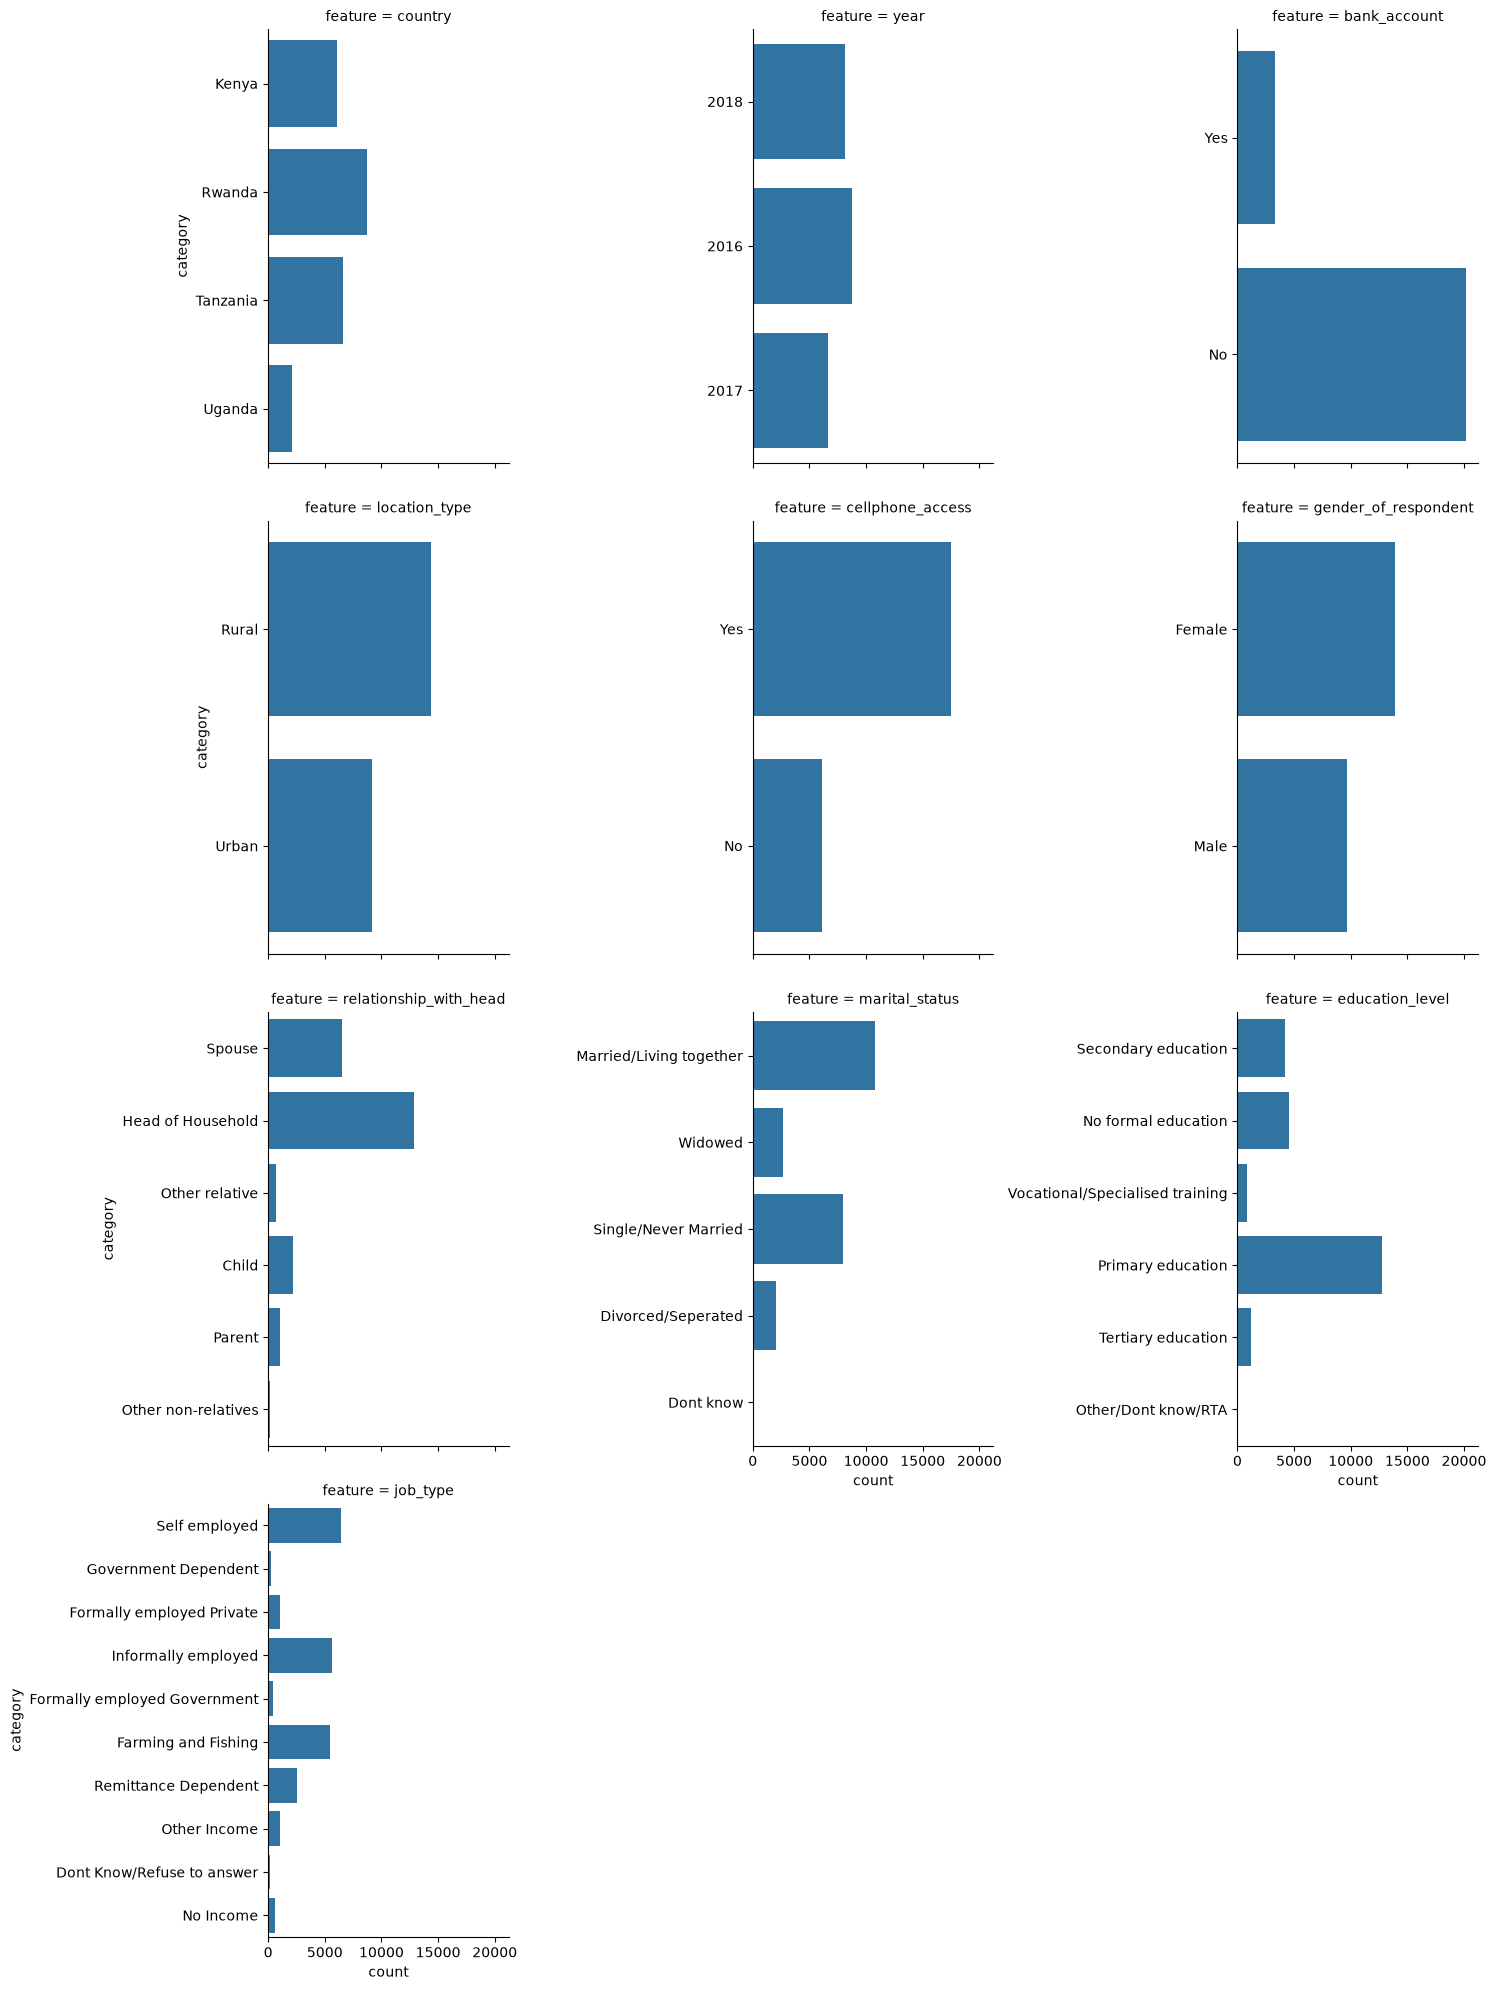

In [95]:
# count plot of categorical columns
g= sns.catplot(
               data=train_melt, 
               y='category',# horizontal barchart 
               col='feature', 
               kind='count', 
               sharey=False, 
               col_wrap=3, )
plt.show()

## Exploratory data analysis on numerical data (training dataset)

In [97]:
num = train_set.select_dtypes(['int', 'float']) # selects only columns with numerical data
#num_cols = list(num)[1:] # numerical column list
#print("numerical column list: ", num_cols)

num_cols = list(num)
num_cols

['household_size', 'age_of_respondent']

In [98]:
# numerical data - training set
train_set_num = train_set[num_cols]
train_set_num.head()

,household_size,age_of_respondent
0,3,24
1,5,70
2,5,26
3,5,34
4,8,26


In [99]:
train_set_num.describe().T # descriptive statistics of numerical columns

,count,mean,std,min,25%,50%,75%,max
household_size,23524.0,3.797483,2.227613,1.0,2.0,3.0,5.0,21.0
age_of_respondent,23524.0,38.805220,16.520569,16.0,26.0,35.0,49.0,100.0


### Data visualization on numerical data (training dataset)

In [21]:
# reshaping the numerical data for data visualization purpose
train_num_melt = pd.melt(
                        train_set[num_cols], 
                         var_name="feature", 
                         value_name="value", 
                         value_vars=num_cols)

In [101]:
train_num_melt.head()

,feature,value
0,household_size,3
1,household_size,5
2,household_size,5
3,household_size,5
4,household_size,8


<Axes: >

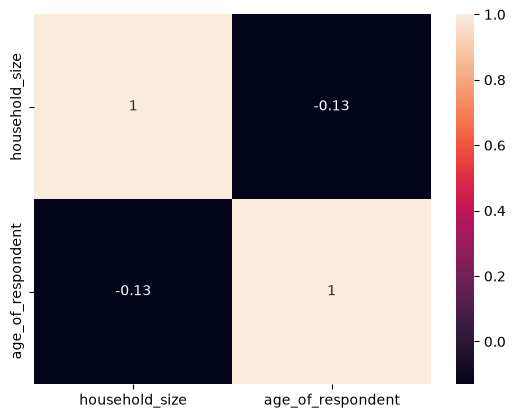

In [102]:
# correlation between household size and age of respondent

sns.heatmap(data = train_set_num.corr(), annot=True)

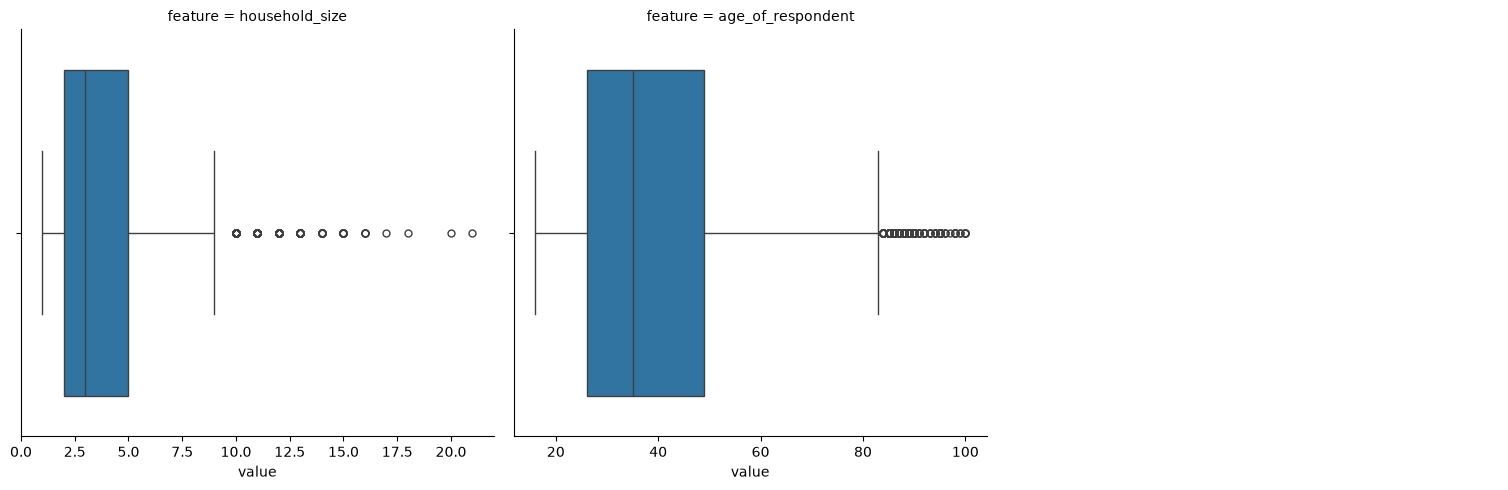

In [103]:
#  distribution plot of numerical columns
g= sns.catplot(
               data=train_num_melt, 
               x='value',# horizontal barchart 
               col='feature', 
               kind='box', 
               sharex=False, 
               col_wrap=3, )
plt.show()

In [104]:
train_set_num.describe().T

,count,mean,std,min,25%,50%,75%,max
household_size,23524.0,3.797483,2.227613,1.0,2.0,3.0,5.0,21.0
age_of_respondent,23524.0,38.805220,16.520569,16.0,26.0,35.0,49.0,100.0


## Repeating data inspection and exploratory data analysis step for the test dataset
----

## Data inspection 

In [105]:
test_set.head() # glimpse of test set

,country,year,uniqueid,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_6056,Urban,Yes,3,30,Male,Head of Household,Married/Living together,Secondary education,Formally employed Government
1,Kenya,2018,uniqueid_6060,Urban,Yes,7,51,Male,Head of Household,Married/Living together,Vocational/Specialised training,Formally employed Private
2,Kenya,2018,uniqueid_6065,Rural,No,3,77,Female,Parent,Married/Living together,No formal education,Remittance Dependent
3,Kenya,2018,uniqueid_6072,Rural,No,6,39,Female,Head of Household,Married/Living together,Primary education,Remittance Dependent
4,Kenya,2018,uniqueid_6073,Urban,No,3,16,Male,Child,Single/Never Married,Secondary education,Remittance Dependent


In [106]:
test_set.info() # column fields information of training data

<class 'pandas.DataFrame'>
RangeIndex: 10086 entries, 0 to 10085
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 10086 non-null  str  
 1   year                    10086 non-null  str  
 2   uniqueid                10086 non-null  str  
 3   location_type           10086 non-null  str  
 4   cellphone_access        10086 non-null  str  
 5   household_size          10086 non-null  int64
 6   age_of_respondent       10086 non-null  int64
 7   gender_of_respondent    10086 non-null  str  
 8   relationship_with_head  10086 non-null  str  
 9   marital_status          10086 non-null  str  
 10  education_level         10086 non-null  str  
 11  job_type                10086 non-null  str  
dtypes: int64(2), str(10)
memory usage: 1.9 MB


In [108]:
test_set.describe().round(2).T # descriptive statistics of numeric field of the testing set.

,count,mean,std,min,25%,50%,75%,max
household_size,10086.0,3.78,2.21,1.0,2.0,3.0,5.0,20.0
age_of_respondent,10086.0,38.31,16.27,16.0,26.0,35.0,48.0,100.0


In [109]:
test_set.select_dtypes("str").describe()  # descriptive statistics of categorical field of the testing set.

,country,year,uniqueid,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
count,10086,10086,10086,10086,10086,10086,10086,10086,10086,10086
unique,4,3,7313,2,2,2,6,5,6,10
top,Rwanda,2016,uniqueid_8535,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Self employed
freq,3745,3745,3,6189,7559,5847,5487,4663,5479,2773


In [110]:
# exploratory data analysis on categorical data.
categ_test = test_set.select_dtypes("str")
print(categ_test.columns)


Index(['country', 'year', 'uniqueid', 'location_type', 'cellphone_access',
       'gender_of_respondent', 'relationship_with_head', 'marital_status',
       'education_level', 'job_type'],
      dtype='str')


In [111]:
### Distribution of categorical data
# count of each category in the categorical columns
cols_test = ['country', 'year','location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type']
for col in cols_test:

    print(test_set[col].value_counts(), '\n', '-----------------------------', '\n')


country
Rwanda      3745
Tanzania    2839
Kenya       2601
Uganda       901
Name: count, dtype: int64 
 ----------------------------- 

year
2016    3745
2018    3502
2017    2839
Name: count, dtype: int64 
 ----------------------------- 

location_type
Rural    6189
Urban    3897
Name: count, dtype: int64 
 ----------------------------- 

cellphone_access
Yes    7559
No     2527
Name: count, dtype: int64 
 ----------------------------- 

gender_of_respondent
Female    5847
Male      4239
Name: count, dtype: int64 
 ----------------------------- 

relationship_with_head
Head of Household      5487
Spouse                 2845
Child                   962
Parent                  465
Other relative          258
Other non-relatives      69
Name: count, dtype: int64 
 ----------------------------- 

marital_status
Married/Living together    4663
Single/Never Married       3447
Widowed                    1107
Divorced/Seperated          868
Dont know                     1
Name: count, dtype: 

In [112]:
# percentage of each category in the categorical columns
for col in cols_test:

    print((test_set[col].\
        value_counts()/test_set[col].\
        value_counts().sum()).round(2)*100, '\n', '-----------------------------', '\n')

country
Rwanda      37.0
Tanzania    28.0
Kenya       26.0
Uganda       9.0
Name: count, dtype: float64 
 ----------------------------- 

year
2016    37.0
2018    35.0
2017    28.0
Name: count, dtype: float64 
 ----------------------------- 

location_type
Rural    61.0
Urban    39.0
Name: count, dtype: float64 
 ----------------------------- 

cellphone_access
Yes    75.0
No     25.0
Name: count, dtype: float64 
 ----------------------------- 

gender_of_respondent
Female    58.0
Male      42.0
Name: count, dtype: float64 
 ----------------------------- 

relationship_with_head
Head of Household      54.0
Spouse                 28.0
Child                  10.0
Parent                  5.0
Other relative          3.0
Other non-relatives     1.0
Name: count, dtype: float64 
 ----------------------------- 

marital_status
Married/Living together    46.0
Single/Never Married       34.0
Widowed                    11.0
Divorced/Seperated          9.0
Dont know                   0.0
Name: co

In [113]:
# reshape training data for visualization purpose
test_set2 = test_set[cols_test]
test_melt = pd.melt(test_set2, 
                     value_vars=cols_test, 
                     var_name= "feature", 
                     value_name="category")
test_melt.head()

,feature,category
0,country,Kenya
1,country,Kenya
2,country,Kenya
3,country,Kenya
4,country,Kenya


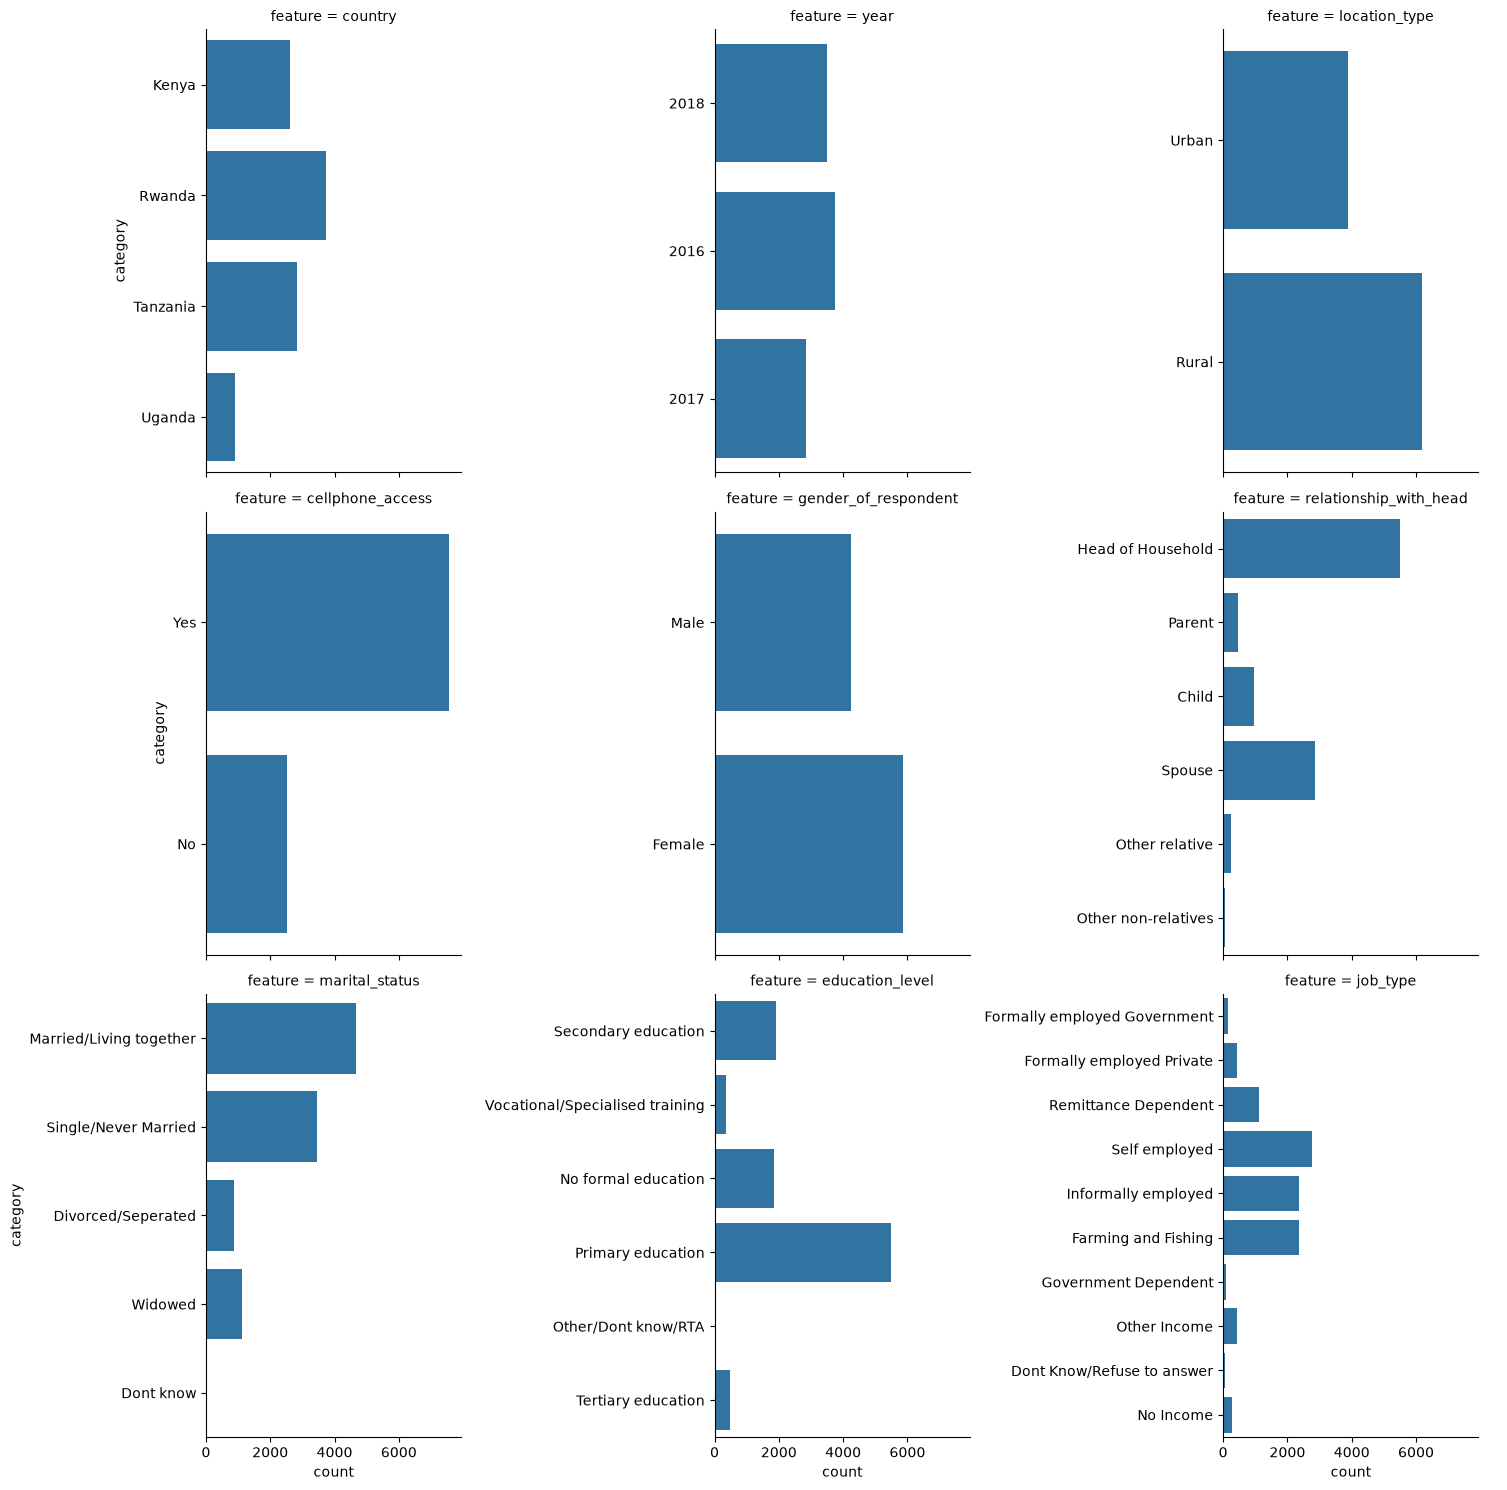

In [114]:
#distribution of variables in each column field.
g= sns.catplot(
               data=test_melt, 
               y='category',# horizontal barchart 
               col='feature', 
               kind='count', 
               sharey=False, 
               col_wrap=3, )
plt.show()

## Preparing data for model training.

It includes:
- re-ordering columns.
- seperating dependent variable from the independent variable in the training dataset.
- spliting the dataset into training and testing sets.

In [116]:
# filtering and re-ordering the column fields for model building purpose
train_cols = [
    'country',
 'year',
 'location_type',
 'cellphone_access',
 'household_size',
 'age_of_respondent',
 'gender_of_respondent',
 'relationship_with_head',
 'marital_status',
 'education_level',
 'job_type',
 'bank_account'] 

test_cols = ['country',
 'year',
 'location_type',
 'cellphone_access',
 'household_size',
 'age_of_respondent',
 'gender_of_respondent',
 'relationship_with_head',
 'marital_status',
 'education_level',
 'job_type']
# creates new traing and testing data with the required columns.
testing_set1 = test_set[test_cols]
training_set1 = train_set[train_cols]

In [117]:
#Separate training features from target
# creating X_train, y_train and X_test variables

X = training_set1.drop(['bank_account'], axis=1)
y = training_set1['bank_account']
X_test = testing_set1

print("X_train shape: ", X.shape)
print("X_test shape: ", X_test.shape)

X_train shape:  (23524, 11)
X_test shape:  (10086, 11)


In [155]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# set label encoder on y variable
le = LabelEncoder() 
y = le.fit_transform(y) 

#splits the data into training and testing dataset
# with ratio of 70:30
# stratification will be implemented to ensure balanced data distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    stratify= y, 
    random_state=42
)

In [156]:
X_train.head()

,country,year,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
5037,Kenya,2018,Urban,No,6,18,Male,Child,Single/Never Married,Primary education,Other Income
12649,Rwanda,2016,Rural,No,3,59,Male,Head of Household,Married/Living together,No formal education,Farming and Fishing
16973,Tanzania,2017,Urban,Yes,1,51,Male,Head of Household,Married/Living together,Primary education,Informally employed
14772,Rwanda,2016,Urban,Yes,1,48,Female,Head of Household,Widowed,Primary education,Other Income
12533,Rwanda,2016,Rural,Yes,9,36,Female,Spouse,Married/Living together,Primary education,Informally employed


In [158]:
y_train

array([0, 0, 0, ..., 0, 1, 0], shape=(16466,))

In [159]:
X_test.head()

,country,year,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
5889,Kenya,2018,Rural,Yes,6,66,Female,Head of Household,Married/Living together,Secondary education,Farming and Fishing
11451,Rwanda,2016,Rural,Yes,2,56,Female,Head of Household,Married/Living together,Secondary education,Formally employed Government
9234,Rwanda,2016,Rural,Yes,5,23,Female,Parent,Single/Never Married,Primary education,Farming and Fishing
2669,Kenya,2018,Rural,Yes,8,16,Male,Child,Single/Never Married,Secondary education,Remittance Dependent
11316,Rwanda,2016,Rural,Yes,5,18,Female,Parent,Single/Never Married,Secondary education,Farming and Fishing


## Machine learning pipeline
The cells below sets up a pipeline to handle missing data, standardize columns and fit a supervised model.

In [160]:
# Using sklearn Pipeline package and transformers.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

#columns list for the training set

categ_cols1 = ['country',
 'location_type',
 'cellphone_access',
 'gender_of_respondent',
 'relationship_with_head',
 'marital_status',
 'education_level',
 'job_type']

# Define data processing for numeric features
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Define data processing for categorical features
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])


# Combine transformers into a single preprocessor steps
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer,categ_cols1 )
])

# Chains the preprocessor step with a final model
ml_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced'))
])

# Fit and predict seamlessly on data frames
ml_pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['country','year','location_type',...,'marital_status','education_level', 'job_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [161]:
predictions1 = ml_pipeline.predict(X_test)
accuracy_score = ml_pipeline.score(X_test,y_test)

In [162]:
print("Logistics regrssion accuracy score: ",accuracy_score)

Logistics regrssion accuracy score:  0.7896004533862284


### Training different model simultanuosly using Pipeline and GridSearch

In [163]:
from sklearn.model_selection import GridSearchCV

#  Create a baseline pipeline with a placeholder estimator
pipeline_01 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression()) # Placeholder
])

#  parameter grid that sets model variables
param_grid = [
    {
        'classifier': [LogisticRegression()],
        'classifier__C': [0.1, 1.0, 10.0]
    },
    {
        'classifier': [RandomForestClassifier(random_state=42)],
        'classifier__n_estimators': [50, 100, 200]
    }
]

#  Grid Search
grid_search = GridSearchCV(pipeline_01, param_grid, cv=5, scoring='f1')
grid_search.fit(X_train, y_train)

# prints results.
print("Best Model & Params:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

# The best pipeline is already fitted and ready to predict!
best_pipeline = grid_search.best_estimator_
predictions = best_pipeline.predict(X_test)


Best Model & Params: {'classifier': RandomForestClassifier(random_state=42), 'classifier__n_estimators': 100}
Best Score: 0.4579093448588013


In [164]:
from sklearn.metrics import classification_report, confusion_matrix

print('Model1:')
print(confusion_matrix(y_test, predictions1))
print(classification_report(y_test, predictions1))
print("\n")
print('Model 2- gridsearch:')
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

Model1:
[[4829 1235]
 [ 250  744]]
              precision    recall  f1-score   support

           0       0.95      0.80      0.87      6064
           1       0.38      0.75      0.50       994

    accuracy                           0.79      7058
   macro avg       0.66      0.77      0.68      7058
weighted avg       0.87      0.79      0.82      7058



Model 2- gridsearch:
[[5684  380]
 [ 593  401]]
              precision    recall  f1-score   support

           0       0.91      0.94      0.92      6064
           1       0.51      0.40      0.45       994

    accuracy                           0.86      7058
   macro avg       0.71      0.67      0.69      7058
weighted avg       0.85      0.86      0.86      7058

